# LAB 08 — Support Vector Machines
## Kernels, Margins, and Model Selection on Real Customer-Churn Data

## Student Information
- **Name:** Abdul Hussain
- **Student ID:** 023-24-0286
- **Section:** H
- **GitHub:** https://github.com/AbdulHussainLehri/ML_Week8
- **Kaggle:** https://www.kaggle.com/abdulhussainbrohi
- **Dataset:** Telco Customer Churn (Kaggle)
- **Dataset Source:** https://www.kaggle.com/datasets/blastchar/telco-customer-churn

---

### Before You Start
- You already studied SVM theory in class (margin, support vectors, kernel trick, C, gamma). This notebook does **not** re-teach that theory.
- This is **not** a "load data → `SVC().fit()` → done" lab. Most marks come from experimentation, visualization and justification, not from the fact that a model trained.
- You already know Python, Pandas, Matplotlib, `train_test_split`, encoding and evaluation metrics from Labs 2-6.
- Each task gives an **objective** and a **question** — not a code recipe. Hints tell you which tool is relevant; you decide how to use it.
- Do **not** provide complete code for every question yourself either — work it out. Every plot needs a written interpretation directly below it.


---

## Part 0 — Recap and Setup

Reload the Telco Customer Churn dataset and reapply the **same** cleaning/encoding pipeline from Labs 2/3/4/6:
- Convert `TotalCharges` to numeric and handle missing values
- Drop `customerID`
- Map `Churn` to 0/1
- One-hot encode categorical columns (`drop_first=True`)
- `train_test_split` with `stratify=y` — use the **same `random_state`** you used in Labs 3/4/6 so results stay comparable


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import time
import warnings

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, roc_curve, roc_auc_score

In [2]:
dataset = pd.read_csv('WA_Fn-UseC_-Telco-Customer-Churn.csv')

print("Dataset Shape: ", dataset.shape)
dataset.head()

Dataset Shape:  (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [3]:
dataset.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [4]:
# TotalCharges is text in the csv, so converting it to numbers first
dataset['TotalCharges'] = pd.to_numeric(dataset['TotalCharges'], errors='coerce')
print("Missing values in TotalCharges:", dataset['TotalCharges'].isnull().sum())

# the missing ones are filled with the median
dataset['TotalCharges'] = dataset['TotalCharges'].fillna(dataset['TotalCharges'].median())

# customerID is just an id so it is dropped
dataset = dataset.drop('customerID', axis=1)

# Churn to 0/1
dataset['Churn'] = dataset['Churn'].map({'No': 0, 'Yes': 1})
print(dataset['Churn'].value_counts())
print(dataset['Churn'].value_counts(normalize=True).round(3))

Missing values in TotalCharges: 11
Churn
0    5174
1    1869
Name: count, dtype: int64
Churn
0    0.735
1    0.265
Name: proportion, dtype: float64


In [5]:
y = dataset['Churn']
x = dataset.drop('Churn', axis=1)

# one-hot encoding for all the text columns
x = pd.get_dummies(x, drop_first=True, dtype=int)

print("x shape after encoding:", x.shape)
print("Missing values in x:", x.isnull().sum().sum())

x shape after encoding: (7043, 30)
Missing values in x: 0


In [6]:
# same random_state and test_size as my earlier labs, and stratify=y because churn is imbalanced
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42, stratify=y)

print("x_train shape:", x_train.shape)
print("x_test shape:", x_test.shape)
print("Churn rate in train:", round(y_train.mean(), 3))
print("Churn rate in test:", round(y_test.mean(), 3))

x_train shape: (5634, 30)
x_test shape: (1409, 30)
Churn rate in train: 0.265
Churn rate in test: 0.265


**Interpretation:** The dataset has 7043 rows and 21 columns. `TotalCharges` had 11 missing values, all from customers with `tenure` = 0, so I filled them with the median. After dropping `customerID` and one-hot encoding, there are 30 features. Only 26.5% of customers churned, so the data is imbalanced. The split is 5634 train / 1409 test with `random_state=42` and `stratify=y`, and the churn rate is 26.5% in both.

**Helper function** to get all four metrics in one call:

In [7]:
def get_scores(y_true, y_pred):
    return {'Accuracy': accuracy_score(y_true, y_pred),
            'Precision': precision_score(y_true, y_pred),
            'Recall': recall_score(y_true, y_pred),
            'F1-score': f1_score(y_true, y_pred)}

---

## Part 1 — Why Scaling Matters for SVM

**Task 1.1 — Objective:** Demonstrate what happens to an SVM when features are not scaled.

**What to do:**
1. Train a linear-kernel SVM (`SVC(kernel='linear')`) directly on your **un-scaled** encoded features.
2. Train a second linear-kernel SVM on the same split after applying `StandardScaler` (fit on train only, transform on train and test).
3. Compare accuracy, F1-score, training time, and any convergence warnings between the two runs.

```python
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler

# unscaled
svm_raw = SVC(kernel='linear', random_state=42)
svm_raw.fit(X_train, y_train)

# scaled  (fit_transform on TRAIN, transform ONLY on TEST)
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s  = scaler.transform(X_test)
```


In [8]:
# first look at how different the feature ranges are
print(x_train[['tenure', 'MonthlyCharges', 'TotalCharges', 'SeniorCitizen', 'Contract_Two year']].describe().loc[['min', 'max', 'std']])

        tenure  MonthlyCharges  TotalCharges  SeniorCitizen  Contract_Two year
min   0.000000       18.400000     18.850000       0.000000           0.000000
max  72.000000      118.750000   8684.800000       1.000000           1.000000
std  24.568744       30.138105   2277.809211       0.369667           0.427858


**Interpretation:** `TotalCharges` goes up to 8684 while the dummy columns are only 0 or 1, so the features differ in scale by thousands of times.

In [9]:
# UN-SCALED linear SVM
# note: when I first ran this without max_iter it was still running after more than 5 minutes
# so I put a limit on the iterations, otherwise I could not continue with the lab
with warnings.catch_warnings(record=True) as w_raw:
    warnings.simplefilter('always')
    start = time.time()
    svm_raw = SVC(kernel='linear', random_state=42, max_iter=100000)
    svm_raw.fit(x_train, y_train)
    time_raw = time.time() - start

pred_raw = svm_raw.predict(x_test)
print("Training time (unscaled): %.2f seconds" % time_raw)
print("Number of warnings:", len(w_raw))
for w in w_raw:
    print("Warning:", str(w.message)[:120])
print(get_scores(y_test, pred_raw))

Training time (unscaled): 1.90 seconds
Number of warnings: 1
{'Accuracy': 0.4137686302342087, 'Precision': 0.17714285714285713, 'Recall': 0.3315508021390374, 'F1-score': 0.2309124767225326}


In [10]:
# SCALED linear SVM (fit on train only, transform on train and test)
scaler = StandardScaler()
x_train_s = scaler.fit_transform(x_train)
x_test_s = scaler.transform(x_test)

with warnings.catch_warnings(record=True) as w_s:
    warnings.simplefilter('always')
    start = time.time()
    svm_scaled = SVC(kernel='linear', random_state=42)
    svm_scaled.fit(x_train_s, y_train)
    time_scaled = time.time() - start

pred_scaled = svm_scaled.predict(x_test_s)
print("Training time (scaled): %.2f seconds" % time_scaled)
print("Number of warnings:", len(w_s))
print(get_scores(y_test, pred_scaled))

Training time (scaled): 0.71 seconds
Number of warnings: 0
{'Accuracy': 0.7892122072391767, 'Precision': 0.6206896551724138, 'Recall': 0.5294117647058824, 'F1-score': 0.5714285714285714}


In [11]:
scaling_table = pd.DataFrame({
    'Model': ['Linear SVM (unscaled)', 'Linear SVM (scaled)'],
    'Accuracy': [accuracy_score(y_test, pred_raw), accuracy_score(y_test, pred_scaled)],
    'Precision': [precision_score(y_test, pred_raw), precision_score(y_test, pred_scaled)],
    'Recall': [recall_score(y_test, pred_raw), recall_score(y_test, pred_scaled)],
    'F1-score': [f1_score(y_test, pred_raw), f1_score(y_test, pred_scaled)],
    'Train time (s)': [time_raw, time_scaled],
    'Warnings': [len(w_raw), len(w_s)]})
scaling_table.round(4)

,Model,Accuracy,Precision,Recall,F1-score,Train time (s),Warnings
0,Linear SVM (unscaled),0.4138,0.1771,0.3316,0.2309,1.9039,1
1,Linear SVM (scaled),0.7892,0.6207,0.5294,0.5714,0.7089,0


**Interpretation:** The unscaled model is far worse (accuracy 0.414, F1 0.231) and raised a convergence warning. The scaled model reached accuracy 0.789 and F1 0.571 with no warnings.

**Questions to answer:**
(a) What differences did you observe between the unscaled and scaled models (accuracy, warnings, training time)?

*Your answer:* The unscaled model got accuracy 0.414 and F1 0.231 with a `ConvergenceWarning`. The scaled model got accuracy 0.789 and F1 0.571, no warning, and trained in 0.71 s. The unscaled time (1.90 s) is misleading because I had to cap `max_iter=100000`; without the cap it ran for more than 5 minutes.

(b) Why does an unscaled linear SVM behave this way, in terms of how the margin/decision boundary is computed?

*Your answer:* A linear SVM finds the maximum-margin boundary using distances between points. A large-valued feature like `TotalCharges` dominates those distances, so the 0/1 dummy columns barely affect the margin. The solver would need very large weights for them, so it struggles to converge.

(c) From this point onward in the lab, which version will you use for every subsequent SVM, and why?

*Your answer:* I will use the scaled version (`x_train_s`, `x_test_s`) for every SVM from here on. The scaler is fitted on the training data only, so there is no leakage.


---

## Part 2 — Kernel Comparison

**Task 2.1 — Objective:** Train and fairly compare SVM classifiers using the linear, RBF and polynomial kernels on your **scaled** features.

**What to do:**
1. Train three `SVC` models — `kernel='linear'`, `kernel='rbf'`, `kernel='poly'` — with the same `random_state`, on the same scaled train split.
2. For each, record: Accuracy, Precision, Recall, F1-score, and number of support vectors (`model.support_.shape[0]`).
3. Assemble a single comparison table (a DataFrame is fine).
4. Plot the confusion matrix for whichever kernel performed best on F1-score.

| Syntax | Description |
|---|---|
| `SVC(kernel=...)` | `'linear'`, `'rbf'`, or `'poly'` |
| `model.support_` | indices of support vectors |
| `model.n_support_` | number of support vectors per class |


In [12]:
kernel_rows = []
kernel_models = {}

for k in ['linear', 'rbf', 'poly']:
    start = time.time()
    m = SVC(kernel=k, random_state=42)
    m.fit(x_train_s, y_train)
    t = time.time() - start

    pred = m.predict(x_test_s)
    row = {'Kernel': k}
    row.update(get_scores(y_test, pred))
    row['Support Vectors'] = m.support_.shape[0]
    row['Train time (s)'] = t
    kernel_rows.append(row)
    kernel_models[k] = m

kernel_table = pd.DataFrame(kernel_rows)
kernel_table.round(4)

,Kernel,Accuracy,Precision,Recall,F1-score,Support Vectors,Train time (s)
0,linear,0.7892,0.6207,0.5294,0.5714,2569,0.7125
1,rbf,0.7928,0.6444,0.4893,0.5562,2661,0.4773
2,poly,0.7892,0.6421,0.4652,0.5395,2739,0.4087


In [13]:
# support vectors per class
for k in kernel_models:
    print(k, "-> support vectors per class (No churn, Churn):", kernel_models[k].n_support_)

best_kernel = kernel_table.sort_values('F1-score', ascending=False).iloc[0]['Kernel']
print("\nBest kernel by F1:", best_kernel)

linear -> support vectors per class (No churn, Churn): [1287 1282]
rbf -> support vectors per class (No churn, Churn): [1432 1229]
poly -> support vectors per class (No churn, Churn): [1485 1254]

Best kernel by F1: linear


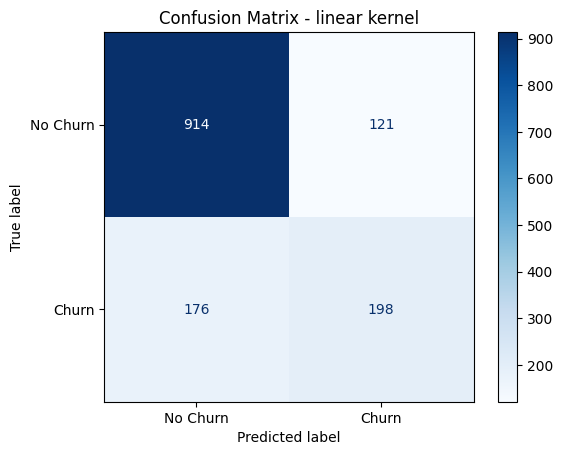

[[914 121]
 [176 198]]


In [14]:
best_pred = kernel_models[best_kernel].predict(x_test_s)
cm = confusion_matrix(y_test, best_pred)

disp = ConfusionMatrixDisplay(cm, display_labels=['No Churn', 'Churn'])
disp.plot(cmap='Blues')
plt.title('Confusion Matrix - %s kernel' % best_kernel)
plt.show()
print(cm)

**Interpretation:** The best kernel by F1 is linear (TN 914, FP 121, FN 176, TP 198). It finds 198 of the 374 real churners and misses 176.

**Questions to answer:**
(a) Which kernel produced the best F1-score on the test set? Does this surprise you given the theory covered in class?

*Your answer:* The linear kernel had the best F1 (0.5714), then RBF (0.5562) and poly (0.5395). It surprised me a little because I expected RBF to win. The one-hot encoded data is probably close to linearly separable. The gap is only 0.015 on a single split, so it is not a clear win.

(b) Which kernel used the most support vectors, and what does a high support-vector count suggest about the complexity of the decision boundary it learned?

*Your answer:* Poly used the most support vectors (2739), then RBF (2661) and linear (2569). That is about 46-49% of the 5634 training points, which means many points sit inside the margin and the classes overlap heavily. The more complex boundaries of poly and RBF did not improve F1.

(c) Based on this evidence, which kernel would you carry forward for hyperparameter tuning in Part 4? Justify with numbers.

*Your answer:* I will carry RBF forward. Its F1 is only 0.015 below linear and it has the best accuracy (0.7928). It also ran with default C and gamma, so tuning has room to help. Poly is dropped because it has the lowest F1 (0.5395) and recall (0.4652) and the most support vectors. Linear's 0.5714 is the score to beat.


---

## Part 3 — Visualizing the Margin: What Does C Actually Do?

**Task 3.1 — Objective:** Reduce your scaled features to 2 dimensions and visualize how an RBF-kernel SVM's decision boundary changes as C increases.

**What to do:**
1. Use `PCA(n_components=2)` on your scaled training features. Report the total explained variance ratio of the two components.
2. Train three RBF-kernel SVMs on this 2-D projection using a small, medium and large C (choose 3 values spanning at least two orders of magnitude, e.g. 0.01, 1, 100).
3. For each C, plot the 2-D decision boundary (mesh grid + `contourf`) with training points overlaid, and report the number of support vectors.

**Hint — Building the Mesh Grid:**
- Build a fine grid of (x, y) spanning slightly beyond your projected data's min/max using `np.meshgrid`.
- Call `model.predict()` on every grid point (flatten, then reshape back to grid shape).
- `plt.contourf(xx, yy, Z, alpha=0.3)` draws shaded regions; `plt.scatter(...)` overlays real points colored by true label.


In [15]:
pca = PCA(n_components=2, random_state=42)
x_train_2d = pca.fit_transform(x_train_s)

print("Explained variance ratio of each component:", pca.explained_variance_ratio_.round(4))
print("Total explained variance by the 2 components: %.4f" % pca.explained_variance_ratio_.sum())

Explained variance ratio of each component: [0.3325 0.1198]
Total explained variance by the 2 components: 0.4523


**Interpretation:** PC1 explains 33.25% and PC2 11.98%, so the 2-D view keeps only 45.23% of the variance and the plots are a rough picture only.

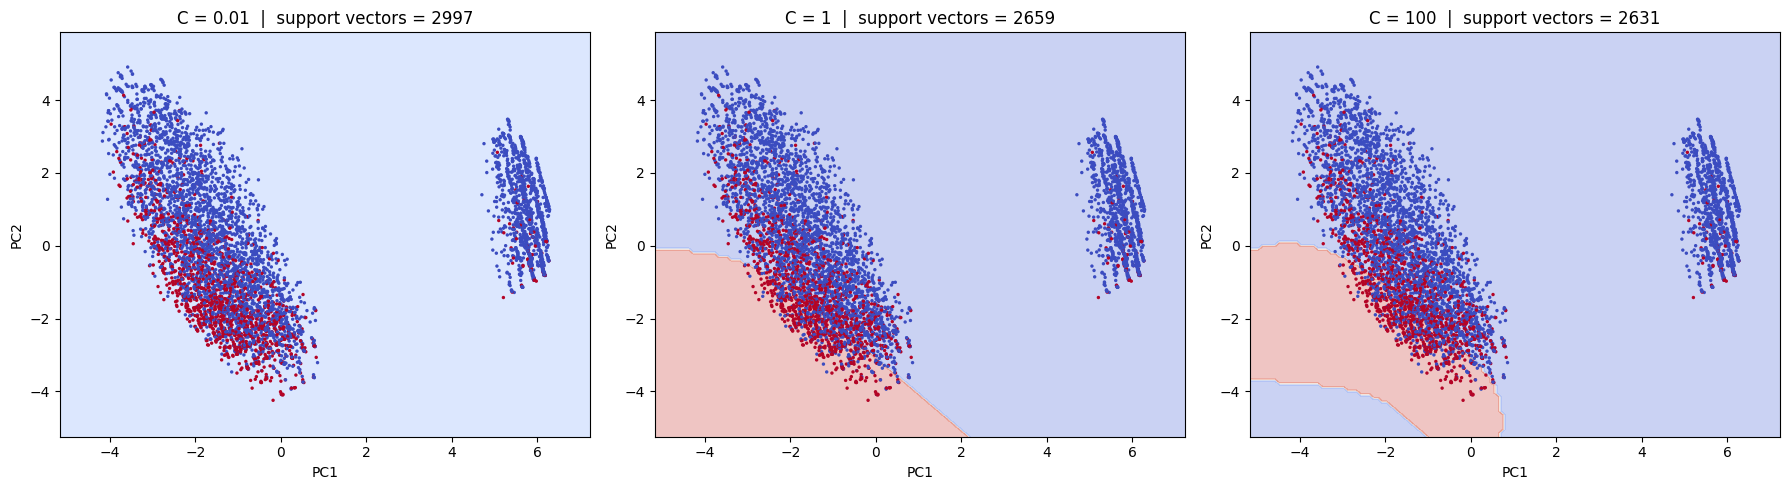

Support vectors for C = [0.01, 1, 100] : [2997, 2659, 2631]


In [16]:
# mesh grid slightly bigger than the data
x_min, x_max = x_train_2d[:, 0].min() - 1, x_train_2d[:, 0].max() + 1
y_min, y_max = x_train_2d[:, 1].min() - 1, x_train_2d[:, 1].max() + 1
xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.1), np.arange(y_min, y_max, 0.1))
grid_points = np.c_[xx.ravel(), yy.ravel()]

C_values = [0.01, 1, 100]
sv_counts_2d = []

plt.figure(figsize=(18, 5))
for i, c in enumerate(C_values):
    m2d = SVC(kernel='rbf', C=c, gamma='scale', random_state=42)
    m2d.fit(x_train_2d, y_train)
    sv_counts_2d.append(m2d.support_.shape[0])

    Z = m2d.predict(grid_points).reshape(xx.shape)

    plt.subplot(1, 3, i + 1)
    plt.contourf(xx, yy, Z, alpha=0.3, cmap='coolwarm')
    plt.scatter(x_train_2d[:, 0], x_train_2d[:, 1], c=y_train, cmap='coolwarm', s=6, edgecolor='none')
    plt.xlabel('PC1')
    plt.ylabel('PC2')
    plt.title('C = %s  |  support vectors = %d' % (c, m2d.support_.shape[0]))

plt.tight_layout()
plt.show()
print("Support vectors for C =", C_values, ":", sv_counts_2d)

In [17]:
# training accuracy of each of the 3 models on the 2-D data, helps me to judge over/underfitting
x_test_2d = pca.transform(x_test_s)
for c in C_values:
    m2d = SVC(kernel='rbf', C=c, gamma='scale', random_state=42).fit(x_train_2d, y_train)
    print("C = %-5s train acc = %.4f | test acc = %.4f | predicts churn for %.1f%% of test rows"
          % (c, m2d.score(x_train_2d, y_train), m2d.score(x_test_2d, y_test), 100 * m2d.predict(x_test_2d).mean()))

C = 0.01  train acc = 0.7346 | test acc = 0.7346 | predicts churn for 0.0% of test rows


C = 1     train acc = 0.7792 | test acc = 0.7786 | predicts churn for 15.8% of test rows


C = 100   train acc = 0.7813 | test acc = 0.7793 | predicts churn for 15.3% of test rows


**Interpretation:** At C = 0.01 the whole plane is one class. At C = 1 there is a smooth churn region at the bottom left, and at C = 100 it is larger and more curved. The small group on the right (PC1 around 5-6) is the 1214 customers with no internet service, who rarely churn (about 7%).

**Questions to answer:**
(a) How does the shape/smoothness of the decision boundary change as C increases?

*Your answer:* The boundary goes from nothing (one class everywhere at C = 0.01), to a smooth, almost straight edge (C = 1), to a larger and more curved region (C = 100). A larger C follows the points more closely, but the change from 1 to 100 is small.

(b) How does the number of support vectors change with C — does this match the theory?

*Your answer:* Support vectors fell as C rose: 2997 (C = 0.01), 2659 (C = 1) and 2631 (C = 100). This matches the theory: a small C allows a wide margin with many violations, and a large C narrows it. The drop from 1 to 100 is only 28 points because the classes overlap so much.

(c) Which C looks like it is overfitting on this 2-D view, and which looks like it is underfitting? Explain the visual evidence.

*Your answer:* C = 0.01 underfits: it predicts no churn for every test row, and its accuracy of 0.7346 equals the share of non-churners. C = 100 is the most flexible, but its train accuracy (0.7813) and test accuracy (0.7793) are almost equal, so it does not really overfit. C = 1 is as accurate and simpler.

(d) Why is this 2-D plot only an APPROXIMATE illustration of the real (high-dimensional) SVM? What could it be misleading you about?

*Your answer:* PCA keeps only 45.23% of the variance and ignores the churn label, so classes that overlap in 2-D may be separable in the full 30 dimensions. Thousands of overlapping points also hide the real density. The 2-D models reach about 0.78 test accuracy against 0.7928 for the full RBF model, so some information is lost.


---

## Part 4 — Systematic Hyperparameter Search

**Task 4.1 — Objective:** Run `GridSearchCV` over a C x gamma grid for an RBF-kernel SVM and select the best configuration using cross-validated F1-score.

**What to do:**
1. Define a parameter grid with at least 3 values of C and at least 3 values of gamma.
2. Run `GridSearchCV(SVC(kernel='rbf'), param_grid, cv=5, scoring='f1')` on your scaled **training** data.
3. Extract `gs.cv_results_` and reshape the mean test scores into a C x gamma grid.
4. Visualize as a heatmap (`imshow` or a pivoted DataFrame) with C and gamma labeled.
5. Refit the best estimator and report its performance on the held-out **test** set.

| Syntax | Description |
|---|---|
| `GridSearchCV(estimator, param_grid, cv, scoring)` | tries every combination via k-fold CV |
| `gs.best_params_` | best hyperparameter combination |
| `gs.cv_results_['mean_test_score']` | mean CV score per combination |


In [18]:
param_grid = {'C': [0.1, 1, 10, 100],
              'gamma': [0.0001, 0.001, 0.01, 0.1]}

start = time.time()
gs = GridSearchCV(SVC(kernel='rbf', random_state=42), param_grid, cv=5, scoring='f1')
gs.fit(x_train_s, y_train)
print("Grid search time: %.1f seconds" % (time.time() - start))

print("Best parameters:", gs.best_params_)
print("Best cross-validated F1: %.4f" % gs.best_score_)

Grid search time: 36.3 seconds
Best parameters: {'C': 100, 'gamma': 0.01}
Best cross-validated F1: 0.5877


In [19]:
# cv_results_ is in the order of the grid, C is the slow one and gamma changes fastest
# so reshaping to (number of C, number of gamma) works
scores = gs.cv_results_['mean_test_score'].reshape(len(param_grid['C']), len(param_grid['gamma']))

heat = pd.DataFrame(scores, index=param_grid['C'], columns=param_grid['gamma'])
heat.index.name = 'C'
heat.columns.name = 'gamma'
print(heat.round(4))

gamma  0.0001  0.0010  0.0100  0.1000
C                                    
0.1    0.0000  0.0000  0.5417  0.4640
1.0    0.0000  0.5746  0.5650  0.5734
10.0   0.5777  0.5857  0.5853  0.5266
100.0  0.5870  0.5710  0.5877  0.5060


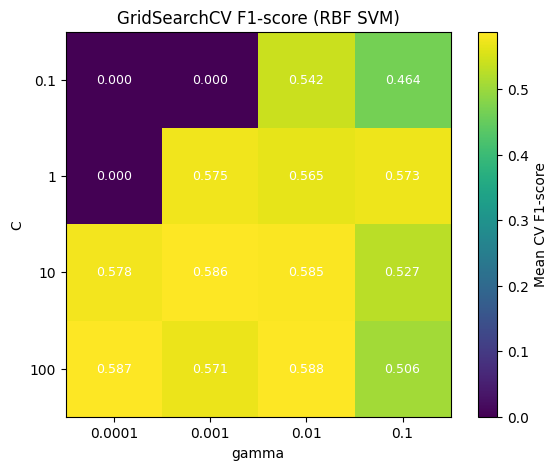

In [20]:
plt.figure(figsize=(7, 5))
plt.imshow(scores, cmap='viridis')
plt.colorbar(label='Mean CV F1-score')
plt.xticks(range(len(param_grid['gamma'])), param_grid['gamma'])
plt.yticks(range(len(param_grid['C'])), param_grid['C'])
plt.xlabel('gamma')
plt.ylabel('C')
plt.title('GridSearchCV F1-score (RBF SVM)')

for i in range(scores.shape[0]):
    for j in range(scores.shape[1]):
        plt.text(j, i, '%.3f' % scores[i, j], ha='center', va='center', color='white', fontsize=9)
plt.show()

**Interpretation:** There is a wide area of similar scores (about 0.57-0.588) for C ≥ 1 and gamma between 0.001 and 0.01. F1 is 0 where C and gamma are both very small, because the model predicts no churn for everyone. It drops to 0.506 at C = 100 with gamma = 0.1, where the model overfits.

Tuned RBF test scores: {'Accuracy': 0.7786, 'Precision': 0.5939, 'Recall': 0.5241, 'F1-score': 0.5568}
Cross-validated F1: 0.5877 | Test F1: 0.5568


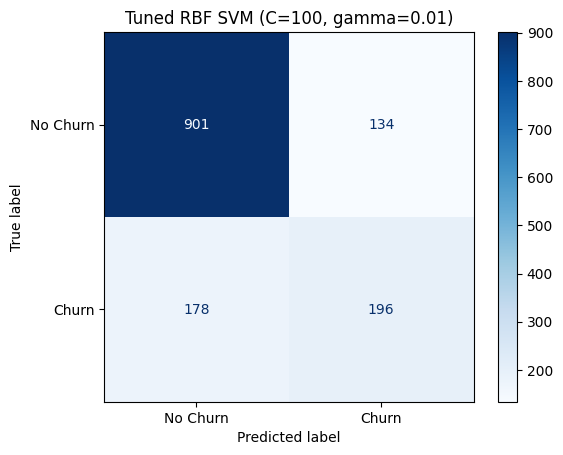

[[901 134]
 [178 196]]


In [21]:
# gs.best_estimator_ is already refitted on the whole training set
best_svm = gs.best_estimator_
pred_best = best_svm.predict(x_test_s)

tuned_scores = get_scores(y_test, pred_best)
print("Tuned RBF test scores:", {k: round(v, 4) for k, v in tuned_scores.items()})
print("Cross-validated F1: %.4f | Test F1: %.4f" % (gs.best_score_, tuned_scores['F1-score']))

cm = confusion_matrix(y_test, pred_best)
ConfusionMatrixDisplay(cm, display_labels=['No Churn', 'Churn']).plot(cmap='Blues')
plt.title('Tuned RBF SVM (C=%s, gamma=%s)' % (gs.best_params_['C'], gs.best_params_['gamma']))
plt.show()
print(cm)

In [22]:
# tuned vs un-tuned RBF from Part 2
compare_tune = pd.DataFrame([kernel_table[kernel_table['Kernel'] == 'rbf'].iloc[0][['Accuracy', 'Precision', 'Recall', 'F1-score']].astype(float),
                             pd.Series(tuned_scores)],
                            index=['RBF default (C=1, gamma=scale)', 'RBF tuned'])
compare_tune.round(4)

,Accuracy,Precision,Recall,F1-score
"RBF default (C=1, gamma=scale)",0.7928,0.6444,0.4893,0.5562
RBF tuned,0.7786,0.5939,0.5241,0.5568


**Interpretation:** The tuned RBF model gets accuracy 0.7786, precision 0.5939, recall 0.5241 and F1 0.5568 on the test set (TN 901, FP 134, FN 178, TP 196).

**Questions to answer:**
(a) What were the best C and gamma values found, and the corresponding cross-validated F1-score?

*Your answer:* The best values are C = 100 and gamma = 0.01, with a cross-validated F1 of 0.5877.

(b) Is there a clear "best region" in the heatmap, or do several combinations perform similarly? What does that tell you?

*Your answer:* There is a wide good region, not a single peak. For example (100, 0.01) gives 0.5877, (100, 0.0001) gives 0.5870, (10, 0.001) gives 0.5857 and (10, 0.01) gives 0.5853, all within 0.003. So the model is not sensitive to the exact values in the middle of the grid and only fails at the extremes.

(c) Did the cross-validated score and the final test-set score agree closely, or was there a gap? What would a large gap suggest?

*Your answer:* CV F1 is 0.5877 and test F1 is 0.5568, a gap of about 0.031. That is small and expected, since I picked the best of 16 combinations on the same CV folds. A large gap would suggest overfitting, a different test distribution, or leakage.

(d) Compare the tuned RBF model's test performance to the un-tuned RBF model from Part 2. Was tuning worth it?

*Your answer:* Not really. F1 only moved from 0.5562 to 0.5568. Accuracy fell (0.7928 to 0.7786) and precision fell (0.6444 to 0.5939), while recall rose (0.4893 to 0.5241). The search took 36 s for 80 fits and still did not beat the linear kernel (0.5714).


---

## Part 5 — Class Imbalance and the Business Trade-off

**Task 5.1 — Objective:** Compare your best RBF-kernel SVM with and without `class_weight='balanced'`, and reason about which is more useful for the business.

**What to do:**
1. Using your best (C, gamma) from Part 4, train two RBF SVMs: `class_weight=None` and `class_weight='balanced'`.
2. Report Precision, Recall, F1-score and confusion matrix for both on the test set.
3. Plot an ROC curve or Precision-Recall curve for the balanced model.


In [23]:
best_C = gs.best_params_['C']
best_gamma = gs.best_params_['gamma']

# probability=True is needed on the balanced model, so I can get predict_proba for the ROC curve later
svm_default = SVC(kernel='rbf', C=best_C, gamma=best_gamma, class_weight=None, random_state=42)
svm_balanced = SVC(kernel='rbf', C=best_C, gamma=best_gamma, class_weight='balanced',
                   probability=True, random_state=42)

svm_default.fit(x_train_s, y_train)
svm_balanced.fit(x_train_s, y_train)

pred_default = svm_default.predict(x_test_s)
pred_balanced = svm_balanced.predict(x_test_s)

balance_table = pd.DataFrame([get_scores(y_test, pred_default), get_scores(y_test, pred_balanced)],
                             index=['class_weight=None', "class_weight='balanced'"])
balance_table.round(4)

,Accuracy,Precision,Recall,F1-score
class_weight=None,0.7786,0.5939,0.5241,0.5568
class_weight='balanced',0.7466,0.5152,0.7701,0.6174


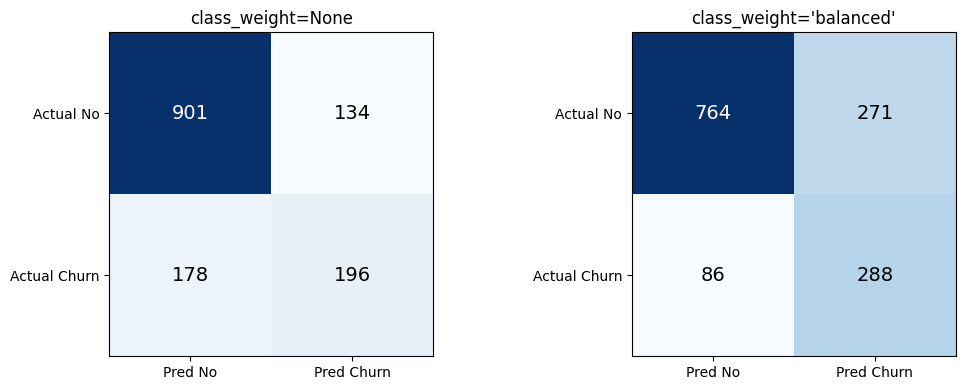

Default  -> TN, FP, FN, TP: [901 134 178 196]
Balanced -> TN, FP, FN, TP: [764 271  86 288]


In [24]:
plt.figure(figsize=(11, 4))
for i, (name, p) in enumerate([('class_weight=None', pred_default), ("class_weight='balanced'", pred_balanced)]):
    plt.subplot(1, 2, i + 1)
    cm = confusion_matrix(y_test, p)
    plt.imshow(cm, cmap='Blues')
    for a in range(2):
        for b in range(2):
            plt.text(b, a, cm[a, b], ha='center', va='center', fontsize=14,
                     color='white' if cm[a, b] > cm.max() / 2 else 'black')
    plt.xticks([0, 1], ['Pred No', 'Pred Churn'])
    plt.yticks([0, 1], ['Actual No', 'Actual Churn'])
    plt.title(name)
plt.tight_layout()
plt.show()

print("Default  -> TN, FP, FN, TP:", confusion_matrix(y_test, pred_default).ravel())
print("Balanced -> TN, FP, FN, TP:", confusion_matrix(y_test, pred_balanced).ravel())

**Interpretation:** With default weights the model catches 196 churners, misses 178 and flags 134 loyal customers by mistake. With `class_weight='balanced'` it catches 288, misses 86 and wrongly flags 271.

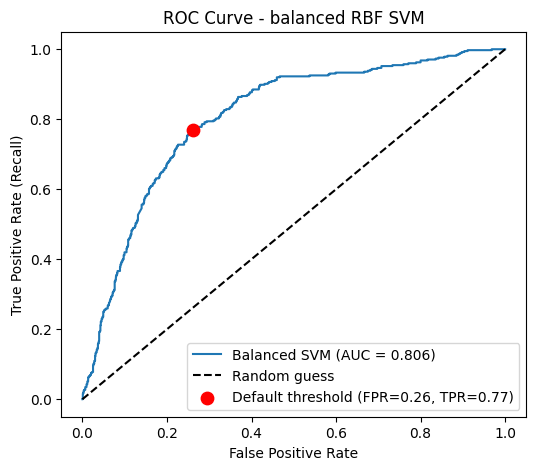

ROC AUC: 0.8058


In [25]:
# probability-like scores from predict_proba (this works because probability=True)
prob_balanced = svm_balanced.predict_proba(x_test_s)[:, 1]

fpr, tpr, thresholds = roc_curve(y_test, prob_balanced)
auc = roc_auc_score(y_test, prob_balanced)

# operating point of the normal predict() (the default threshold)
tn, fp, fn, tp = confusion_matrix(y_test, pred_balanced).ravel()
op_fpr = fp / (fp + tn)
op_tpr = tp / (tp + fn)

plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, label='Balanced SVM (AUC = %.3f)' % auc)
plt.plot([0, 1], [0, 1], 'k--', label='Random guess')
plt.scatter([op_fpr], [op_tpr], color='red', s=80, zorder=5, label='Default threshold (FPR=%.2f, TPR=%.2f)' % (op_fpr, op_tpr))
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate (Recall)')
plt.title('ROC Curve - balanced RBF SVM')
plt.legend(loc='lower right')
plt.show()
print("ROC AUC:", round(auc, 4))

**Interpretation:** The curve is well above the random-guess line with an AUC of 0.806. The default threshold (red dot, FPR = 0.26, TPR = 0.77) is on the steep part of the curve, so moving it would give little extra recall for many more false alarms.

**Questions to answer:**
(a) Precisely how did precision and recall move when you switched to `class_weight='balanced'`? Give the numbers.

*Your answer:* Precision fell from 0.5939 to 0.5152 (-0.0787) and recall rose from 0.5241 to 0.7701 (+0.2460). F1 went from 0.5568 to 0.6174 and accuracy from 0.7786 to 0.7466. False negatives dropped from 178 to 86 and false positives rose from 134 to 271.

(b) Is it more costly to miss an actual churner (false negative) or wrongly flag a loyal customer (false positive)? Which model would you deploy?

*Your answer:* A missed churner (false negative) costs more: the company loses that customer's revenue and must pay to acquire a new one. A false positive only costs a retention offer. The balanced model avoids 92 missed churners (178 - 86) for 137 extra false alarms (271 - 134), about 1.5 per churner caught. I would deploy the balanced model. I don't have real cost figures, so this is an assumption.

(c) SVM does not directly output a "probability of churn" like Logistic Regression. What did you have to enable in `SVC()` to get probability-like scores?

*Your answer:* I had to set `probability=True` in `SVC()`. It uses Platt scaling with an internal 5-fold cross-validation, which makes training slower, and then `predict_proba()` works. `decision_function()` is an alternative for the ROC curve.


---

## Part 6 — Model Showdown: SVM vs. Everything Else

**Task 6.1 — Objective:** Build a single comparison table across all five algorithms (Decision Tree, Random Forest, Logistic Regression, KNN, SVM) and select ONE final model for production.

**What to do:**
1. Build a table: one row per model, columns Accuracy / Precision / Recall / F1-score. Re-run earlier models here on the same split if you don't have saved numbers.
2. Produce ONE bar chart comparing F1-score across all five models.


I did not have saved numbers from the earlier labs, so I re-ran the models on this lab's split, with a small grid search for Decision Tree, Random Forest and KNN.

In [26]:
# Decision Tree (tuned a bit)
gs_dt = GridSearchCV(DecisionTreeClassifier(random_state=42),
                     {'max_depth': [3, 5, 7, 10, None], 'min_samples_leaf': [1, 5, 10, 20]},
                     cv=5, scoring='f1')
gs_dt.fit(x_train, y_train)
print("DT best:", gs_dt.best_params_)

# Random Forest (tuned a bit)
gs_rf = GridSearchCV(RandomForestClassifier(random_state=42),
                     {'n_estimators': [100, 200], 'max_depth': [5, 10, None], 'min_samples_leaf': [1, 5]},
                     cv=5, scoring='f1')
gs_rf.fit(x_train, y_train)
print("RF best:", gs_rf.best_params_)

# Logistic Regression (scaled)
log_reg = LogisticRegression(max_iter=1000, random_state=42)
log_reg.fit(x_train_s, y_train)

# KNN (scaled, choosing k with CV)
gs_knn = GridSearchCV(KNeighborsClassifier(), {'n_neighbors': [3, 5, 7, 9, 11, 15, 21]}, cv=5, scoring='f1')
gs_knn.fit(x_train_s, y_train)
print("KNN best:", gs_knn.best_params_)

DT best: {'max_depth': 7, 'min_samples_leaf': 1}


RF best: {'max_depth': 10, 'min_samples_leaf': 1, 'n_estimators': 100}


KNN best: {'n_neighbors': 21}


In [27]:
# which SVM is my best one? comparing the two from Part 5 on F1
if f1_score(y_test, pred_balanced) >= f1_score(y_test, pred_default):
    final_svm, final_svm_pred, svm_label = svm_balanced, pred_balanced, 'SVM (RBF tuned, balanced)'
else:
    final_svm, final_svm_pred, svm_label = svm_default, pred_default, 'SVM (RBF tuned)'
print("Best SVM:", svm_label)

showdown = pd.DataFrame([
    get_scores(y_test, gs_dt.predict(x_test)),
    get_scores(y_test, gs_rf.predict(x_test)),
    get_scores(y_test, log_reg.predict(x_test_s)),
    get_scores(y_test, gs_knn.predict(x_test_s)),
    get_scores(y_test, final_svm_pred)],
    index=['Decision Tree', 'Random Forest', 'Logistic Regression', 'KNN', svm_label])
showdown.round(4)

Best SVM: SVM (RBF tuned, balanced)


,Accuracy,Precision,Recall,F1-score
Decision Tree,0.7906,0.6208,0.5428,0.5792
Random Forest,0.8070,0.6711,0.5348,0.5952
Logistic Regression,0.8070,0.6584,0.5668,0.6092
KNN,0.7708,0.5702,0.5535,0.5617
"SVM (RBF tuned, balanced)",0.7466,0.5152,0.7701,0.6174


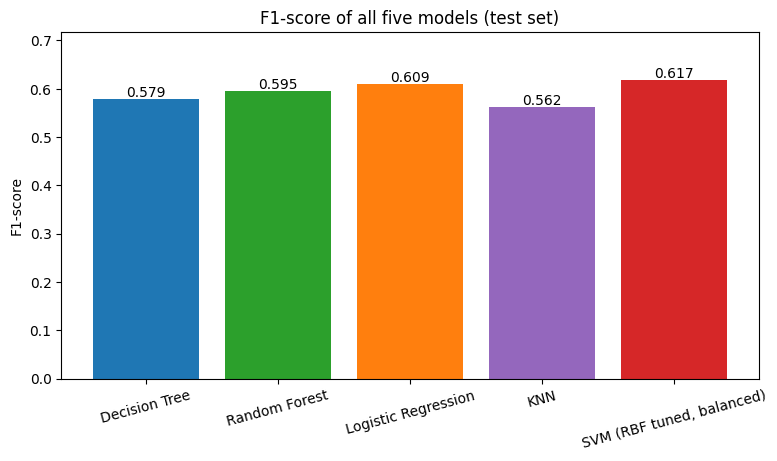

In [28]:
plt.figure(figsize=(9, 4.5))
bars = plt.bar(showdown.index, showdown['F1-score'], color=['tab:blue', 'tab:green', 'tab:orange', 'tab:purple', 'tab:red'])
for b in bars:
    plt.text(b.get_x() + b.get_width() / 2, b.get_height() + 0.005, '%.3f' % b.get_height(), ha='center')
plt.ylabel('F1-score')
plt.title('F1-score of all five models (test set)')
plt.xticks(rotation=15)
plt.ylim(0, showdown['F1-score'].max() + 0.1)
plt.show()

In [29]:
# training times for the question about computational cost
def time_fit(model, xa, ya):
    s = time.time()
    model.fit(xa, ya)
    return time.time() - s

print("Decision Tree (best params): %.2f s" % time_fit(DecisionTreeClassifier(random_state=42, **gs_dt.best_params_), x_train, y_train))
print("Random Forest (best params): %.2f s" % time_fit(RandomForestClassifier(random_state=42, **gs_rf.best_params_), x_train, y_train))
print("Logistic Regression: %.2f s" % time_fit(LogisticRegression(max_iter=1000), x_train_s, y_train))
print("SVM RBF (best params, no probability): %.2f s" % time_fit(SVC(kernel='rbf', C=best_C, gamma=best_gamma, class_weight='balanced'), x_train_s, y_train))

Decision Tree (best params): 0.01 s


Random Forest (best params): 0.30 s
Logistic Regression: 0.01 s


SVM RBF (best params, no probability): 1.41 s


**Interpretation:** All five models have F1 between 0.56 and 0.62. The SVM is highest and KNN is lowest. Training times: Decision Tree 0.01 s, Logistic Regression 0.01 s, Random Forest 0.30 s, SVM 1.41 s.

**Questions to answer:**
(a) Which model wins on F1-score? Which wins on recall? Are they the same model?

*Your answer:* The balanced SVM wins on F1 (0.6174, Logistic Regression is next at 0.6092) and on recall (0.7701 vs 0.5668 for Logistic Regression), so it is the same model. One caveat: only the SVM used `class_weight='balanced'`, so part of its recall advantage comes from that and not from the algorithm.

(b) SVM is generally slower to train than Decision Tree/Random Forest here. Was the extra cost worth it?

*Your answer:* The SVM trains in 1.41 s against 0.01 s for Decision Tree and Logistic Regression and 0.30 s for Random Forest, plus 36 s for the grid search. That is small in absolute terms. On F1 it gains only +0.008 over Logistic Regression, but the recall gain (0.77 vs 0.57) makes it modestly worth it.

(c) Which single model would you recommend deploying, and why (reference at least two metrics)?

*Your answer:* I would deploy the balanced RBF SVM. It has the best recall (0.7701) and F1 (0.6174). The cost is lower precision (0.5152) and accuracy (0.7466). Logistic Regression (F1 0.6092, accuracy 0.8070) is the simpler backup.


---

## Part 7 — Final Predictions and Wrap-Up

**Task 7.1 — Objective:** Generate a predictions file and write a short executive summary.

**What to do:**
1. Using your final chosen model, generate predictions on the test set and save `svm_predictions.csv` with true label, predicted label, and predicted churn probability/score.
2. Write a 5-8 sentence Executive Summary below: which model you chose, key metrics, the main trade-off you made in Part 5, and one limitation of your analysis.


In [30]:
final_pred = final_svm.predict(x_test_s)
final_prob = final_svm.predict_proba(x_test_s)[:, 1] if hasattr(final_svm, 'probability') and final_svm.probability else final_svm.decision_function(x_test_s)

predictions = pd.DataFrame({'True Label': y_test.values,
                            'Predicted Label': final_pred,
                            'Churn Probability': final_prob.round(4)})
predictions.to_csv('svm_predictions.csv', index=False)

print(predictions.shape)
print("Correct predictions: %.2f%%" % (100 * (predictions['True Label'] == predictions['Predicted Label']).mean()))
predictions.head(10)

(1409, 3)
Correct predictions: 74.66%


,True Label,Predicted Label,Churn Probability
0,0,0,0.0606
1,0,1,0.6042
2,0,0,0.0402
3,0,0,0.2548
4,0,0,0.0390
5,0,1,0.6119
6,0,1,0.3621
7,0,0,0.1578
8,0,0,0.0585
9,1,1,0.4751


**Interpretation:** `svm_predictions.csv` has 1409 rows with the true label, predicted label and churn probability (from `predict_proba`). 74.66% of predictions are correct, which matches the Part 5 accuracy.

**Executive Summary**

I chose an RBF-kernel SVM (C = 100, gamma = 0.01, `class_weight='balanced'`) trained on StandardScaler-scaled features. On the test set it gets recall 0.770, precision 0.515, F1 0.617, accuracy 0.747 and ROC AUC 0.806, and it had the best F1 and recall of the five models. The main trade-off in Part 5 was accepting lower precision (0.594 to 0.515) and about 3 points of accuracy to raise recall from 0.524 to 0.770, so it misses 86 churners instead of 178 and gives 137 more false alarms. I think this is worth it because losing a customer costs more than a retention offer. Scaling was essential, since the unscaled linear SVM got only 41% accuracy. One limitation is that I used a single train/test split and only the SVM got class weights, so the small F1 gap over Logistic Regression (0.617 vs 0.609) may not be real. I also had no real cost figures, so the business conclusion rests on an assumption.

**Final Reflection**
(a) What was the single most surprising result in this lab?

*Your answer:* Tuning C and gamma (80 fits) gave almost nothing (test F1 0.5562 to 0.5568), but adding `class_weight='balanced'` lifted F1 to 0.6174 and recall from 0.52 to 0.77. The unscaled SVM's accuracy (0.414) was also worse than always predicting no churn.

(b) If you had one more hour, what would you try next?

*Your answer:* I would give `class_weight='balanced'` to the other models for a fair comparison, tune the decision threshold using the predicted probabilities, and repeat the experiment on a few random states.
